In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from models.dataset_views import load_control_dataset
from eval.rollout import rollout_controller
from eval.metrics import rollout_metrics
from visualization import plot_states_and_input, animate_cart_pendulum

DATASET  = ROOT / "data/full_example/random_walk_dataset.npz"
ds = load_control_dataset(DATASET)
print(ds.states.shape, ds.inputs.shape, ds.initial_state)

(500, 1000, 4) (500, 1000, 1) [0.01447063 0.06920296 0.17453293 0.84325554]


In [2]:
from controllers.sindy_mpc import SINDyMPCController, train_sindy_mpc

ARTIFACT    = ROOT / "artifacts/controllers/sindy_mpc.pkl"
FORCE_LIMIT = 5.0

if ARTIFACT.exists():
    controller = SINDyMPCController.load(ARTIFACT)
    if float(getattr(controller, "force_limit", 1.0)) < 4.5:
        print(f"  Artifact force_limit={controller.force_limit} N is below 4.5 N — retraining.")
        ARTIFACT.unlink()
if not ARTIFACT.exists():
    controller = train_sindy_mpc(ds, seed=0, force_limit=FORCE_LIMIT, t_end=20.0, dt=0.02)
    controller.save(ARTIFACT)
    print(f"saved {ARTIFACT}")
else:
    print(f"loaded {ARTIFACT}  "
          f"(horizon={controller.metadata.get('horizon')}  "
          f"force_limit={controller.force_limit})")
print("Learned equations:")
for eq in controller.metadata["model"]["equations"]:
    print(" ", eq)

/Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/.venv/lib/python3.12/site-packages/cvxpy/problems/problem.py:1510: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


saved /Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/artifacts/controllers/sindy_mpc.pkl
Learned equations:
  x_next = 1*x + 0.01003*x_dot
  x_dot_next = 0.9999*x_dot + 0.007078*u + -0.02327*sin(theta)
  theta_next = 1*theta + 0.01002*theta_dot
  theta_dot_next = 0.9998*theta_dot + 0.2135*sin(theta) + 0.01827*u*cos(theta)


In [3]:
print("A (equilibrium linearisation):")
A = np.asarray(controller.metadata["A"])
for row in A:
    print(" ", np.array2string(row, precision=5, suppress_small=True))
print("B:", np.asarray(controller.metadata["B"]).ravel())
print(f"Horizon N = {controller.metadata.get('horizon')}  "
      f"force_limit = {controller.force_limit} N")
print(f"best_tuning_score = {controller.metadata.get('best_tuning_score'):.4g}")

A (equilibrium linearisation):
  [1.      0.01003 0.      0.     ]
  [ 0.       0.99995 -0.02327  0.     ]
  [0.      0.      0.99999 0.01002]
  [0.      0.      0.21353 0.99981]
B: [0.         0.00707802 0.         0.01826813]
Horizon N = 20  force_limit = 5.0 N
best_tuning_score = 167.4


In [4]:
T_END = 20.0
DT    = 0.02


def run_fixed_and_jittered(controller, n_jitter=8, seed=0):
    rng = np.random.default_rng(seed)
    jitter_scale = np.array([0.02, 0.05, 0.03, 0.1])
    force_limit = float(getattr(controller, "force_limit", 5.0))
    cases = [("fixed", ds.initial_state)]
    for i in range(n_jitter):
        cases.append((f"jitter_{i:02d}", ds.initial_state + rng.normal(scale=jitter_scale)))
    rows, rollouts = [], {}
    for label, x0 in cases:
        result = rollout_controller(controller, x0, t_end=T_END, dt=DT, force_limit=force_limit)
        metrics = rollout_metrics(result.t, result.y, result.u, result.control_times_sec)
        rows.append({"case": label, **metrics})
        rollouts[label] = result
    rows.sort(key=lambda r: (not bool(r.get("success")), float(r.get("cost", np.inf))))
    return rows, rollouts


def show_case(label, result, title):
    fig, _ = plot_states_and_input(result.t, result.y, result.u,
                                   title=title, theta_in_degrees=True)
    plt.show()

    metrics = rollout_metrics(result.t, result.y, result.u)
    t_settle = metrics.get("settle_and_remain_time")
    t = result.t
    theta_deg = np.degrees(result.y[2, :])
    success = bool(metrics.get("success", False))

    fig2, axes2 = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    ax = axes2[0]
    ax.plot(t, theta_deg, color="steelblue", linewidth=1.5, label="\u03b8 (deg)")
    ax.axhline( 2.0, color="green", linestyle="--", linewidth=1, label="\u00b12\u00b0 tolerance")
    ax.axhline(-2.0, color="green", linestyle="--", linewidth=1)
    if t_settle is not None:
        ax.axvspan(t_settle, float(t[-1]), alpha=0.13, color="green",
                   label=f"Settled  t_s={t_settle:.2f} s")
    ax.axvline(float(t[-1]) / 2, color="gray", linestyle=":", linewidth=1, label="t_end/2")
    ax.set_ylabel("\u03b8 (degrees)")
    ax.set_title(f"{title}  \u2014  {'\u2713 SUCCESS' if success else '\u2717 FAIL'}")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, alpha=0.3)

    ax2 = axes2[1]
    ax2.plot(t, result.u, color="darkorange", linewidth=1.4, label="Force (N)")
    ax2.axhline(0, color="k", linewidth=0.5)
    ax2.set_xlabel("time (s)")
    ax2.set_ylabel("force (N)")
    ax2.legend(loc="upper right", fontsize=8)
    ax2.grid(True, alpha=0.3)
    fig2.tight_layout()
    plt.show()

    if t_settle is not None:
        post = float(t[-1]) - t_settle
        flag = "PASS" if t_settle <= float(t[-1]) / 2 else "FAIL"
        print(f"  settle_t={t_settle:.2f} s  post_settle={post:.2f} s  "
              f"[{flag}: t_s \u2264 {float(t[-1])/2:.0f} s]")
    else:
        print("  Did not settle and remain within all tolerances.")
    try:
        anim = animate_cart_pendulum(result.t, result.y, pendulum_length=0.5, stride=5)
        display(HTML(anim.to_jshtml()))
    except Exception as exc:
        print(f"  Animation skipped ({exc})")

In [5]:
rows, rollouts = run_fixed_and_jittered(controller, n_jitter=8, seed=5)
successes = sum(1 for r in rows if r.get("success"))
print(f"Successes: {successes}/{len(rows)}  "
      f"(force_limit={getattr(controller,'force_limit',5.0)} N, t_end={T_END} s)")
for r in rows:
    t_s = r.get("settle_and_remain_time")
    t_s_str = f"{t_s:.2f} s" if t_s is not None else "  None  "
    print(f"  {r['case']:15s}  success={str(r.get('success')):5s}  "
          f"settle_t={t_s_str:8s}  cost={r.get('cost', float('nan')):.4g}")

Successes: 9/9  (force_limit=5.0 N, t_end=20.0 s)
  jitter_06        success=True   settle_t=3.10 s    cost=66.07
  jitter_07        success=True   settle_t=3.34 s    cost=92.15
  jitter_03        success=True   settle_t=3.36 s    cost=95.44
  jitter_01        success=True   settle_t=3.36 s    cost=96.1
  jitter_04        success=True   settle_t=3.50 s    cost=112
  jitter_02        success=True   settle_t=3.50 s    cost=113.2
  jitter_05        success=True   settle_t=3.64 s    cost=128.9
  fixed            success=True   settle_t=3.86 s    cost=167.4
  jitter_00        success=True   settle_t=3.94 s    cost=184.5


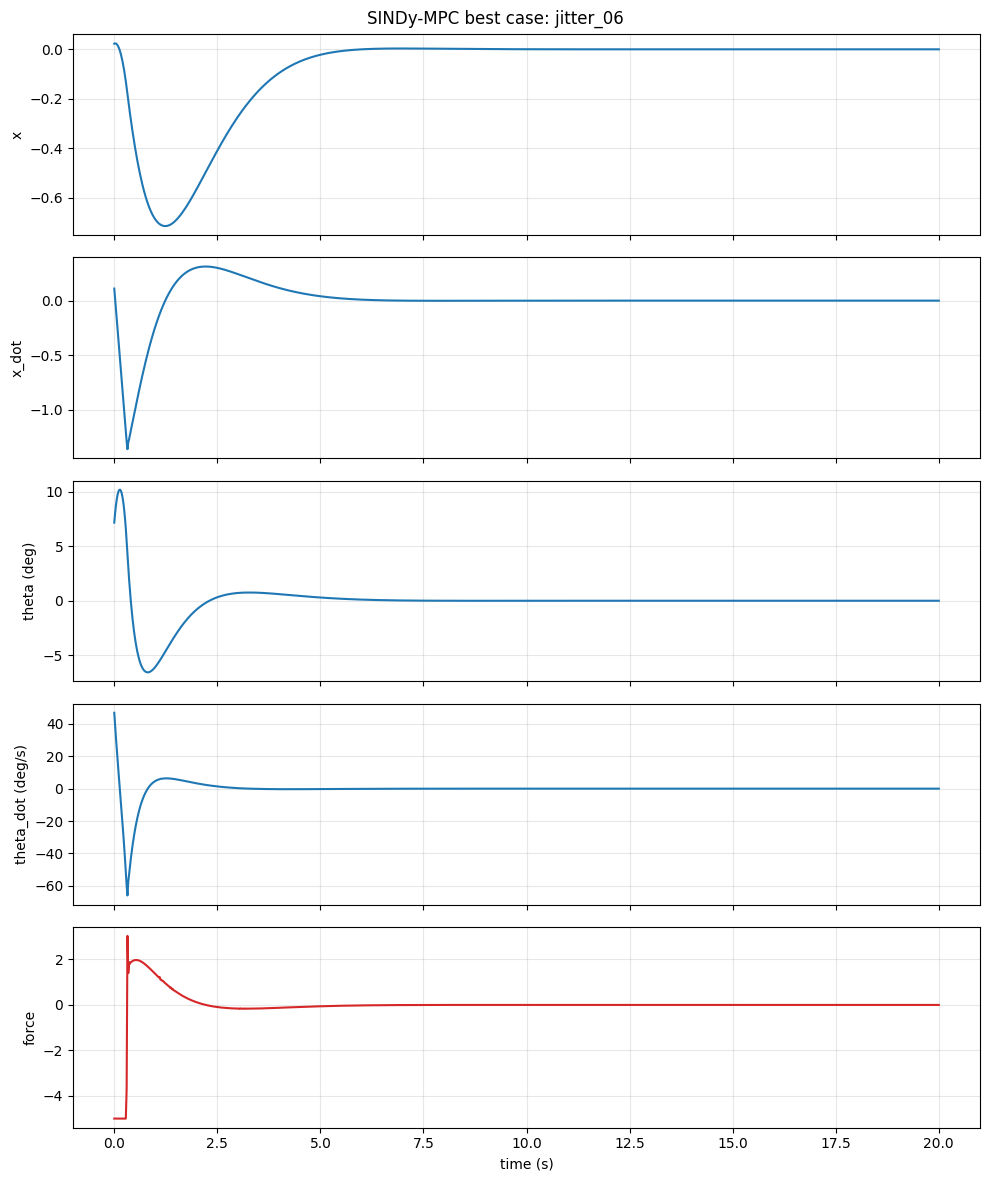

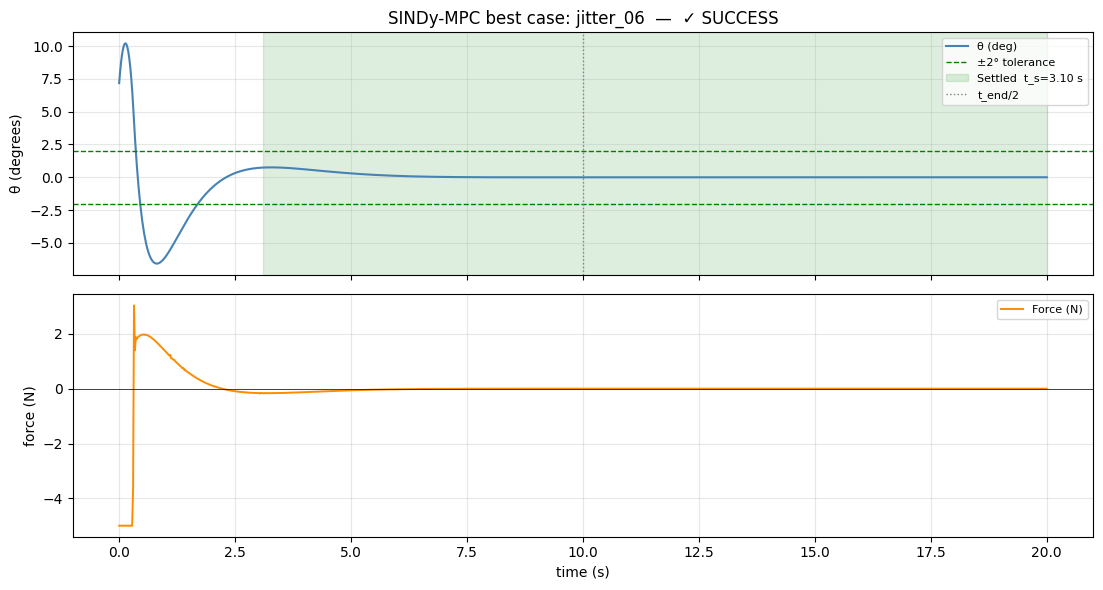

  settle_t=3.10 s  post_settle=16.90 s  [PASS: t_s ≤ 10 s]


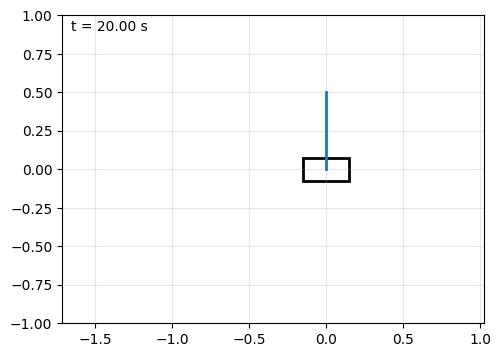

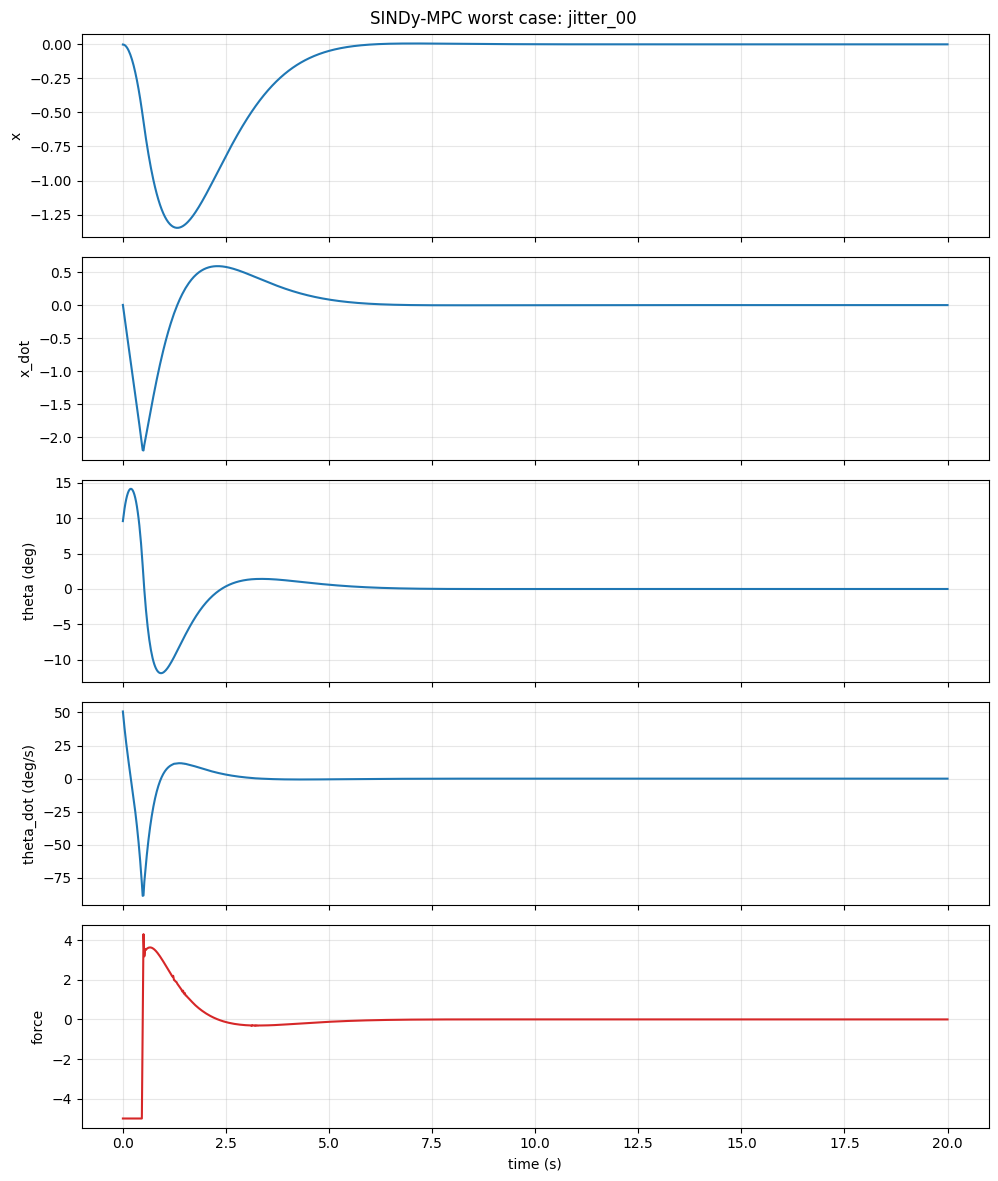

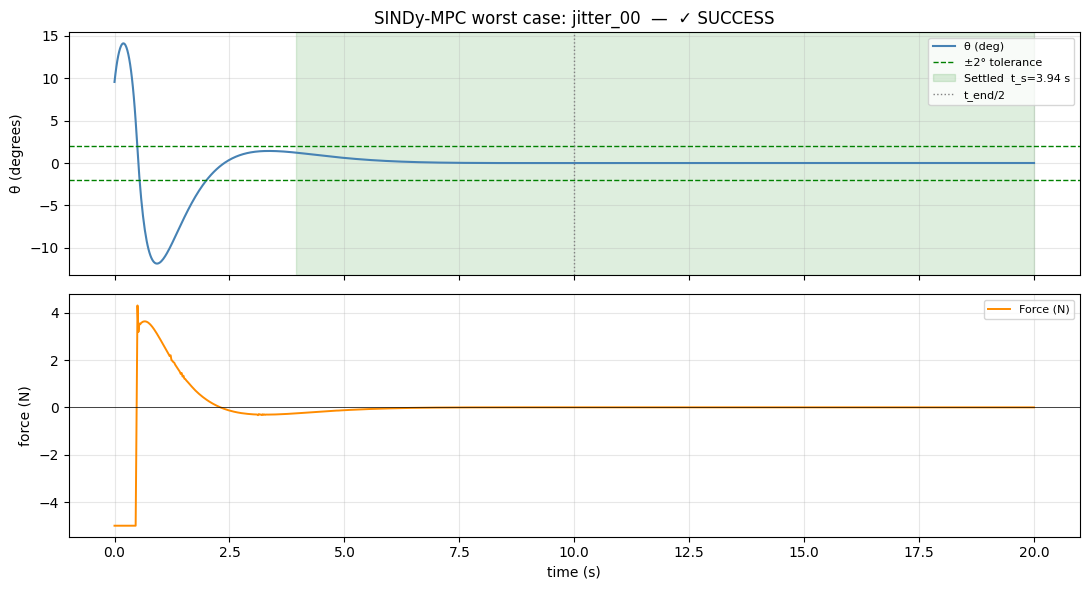

  settle_t=3.94 s  post_settle=16.06 s  [PASS: t_s ≤ 10 s]


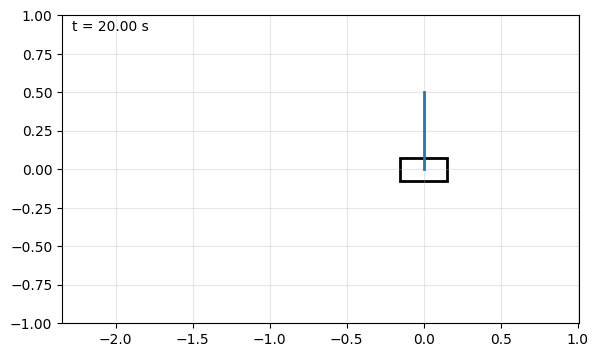

In [6]:
best  = rows[0]["case"]
worst = rows[-1]["case"]
show_case(best,  rollouts[best],  f"SINDy-MPC best case: {best}")
show_case(worst, rollouts[worst], f"SINDy-MPC worst case: {worst}")